# CA2 — Online Retail Sales Analysis & Interactive Dashboard

| Field | Details |
| :--- | :--- |
| **Institution** | CCT College Dublin |
| **Programme** | BSc Computing and IT (Stage 4, Semester 1) |
| **Module** | Data Visualisation and Communication |
| **Assessment** | Continuous Assessment 2 (CA2 — 60%) |
| **Student Name & ID** | Caio Jacob (`2023168`) |
| **Lecturer** | Taufique Ahmed |
| **GitHub Repository** | [https://github.com/CCT-Dublin/CA2_Data_Visualisation_and_Communication_Caio_Jacob_2023168](https://github.com/CCT-Dublin/CA2_Data_Visualisation_and_Communication_Caio_Jacob_2023168) |
| **Video Walkthrough (Google Drive)** | *[Add Google Drive shareable link before final submission]* |

---

## 1. Project Introduction

### 1.1 Business Context
A UK-based online gift wholesaler has experienced rapid sales growth across domestic and international markets, accumulating over half a million transactional line items between **December 2010 and December 2011**. Despite this commercial growth, the company has not yet established a structured analytics workflow. As a result, management lacks clear, visual visibility into revenue drivers, product performance, regional market concentration, seasonal patterns, and customer purchasing behaviour.

### 1.2 Project Objective
Acting as a data analyst for the retailer, the objective of this project is to transform raw transactional records (`Online Retail.xlsx`) into reliable, decision-ready business intelligence through:
1. **Rigorous Data Quality Assessment & Cleaning** — identifying and resolving data integrity issues with clear business justification.
2. **Exploratory Data Analysis (EDA)** — producing well-crafted static visualisations (`Matplotlib` and `Seaborn`) paired with statistical interpretation.
3. **Interactive Management Dashboard** — delivering a functional, executive-friendly dashboard (`Plotly` and `ipywidgets`) that enables managers to filter and explore performance dynamically.

### 1.3 Key Business Questions
This analysis is structured to answer five core management questions:
1. **Temporal Performance:** How do revenue and order volume evolve over time, and what seasonal or operational (day/hour) patterns exist?
2. **Product Drivers:** Which products contribute most to total revenue versus unit volume, and how concentrated are product sales?
3. **Regional Markets:** How dependent is the business on the United Kingdom, and which international markets show the strongest revenue potential?
4. **Order & Pricing Dynamics:** What does a typical order look like in terms of value and quantity, and how do wholesale outliers affect average metrics?
5. **Customer Concentration:** How is revenue distributed across identifiable customers, and what distinguishes high-value repeat buyers from occasional purchasers?

### 1.4 Notebook Roadmap
- **Section 1:** Project Introduction *(current section)*
- **Section 2:** Data Understanding
- **Section 3:** Data Quality Assessment & Cleaning
- **Section 4:** Feature Engineering
- **Section 5:** Exploratory Data Analysis (Static Visualisations)
- **Section 6:** Interactive Management Dashboard
- **Section 7:** Business Insights & Recommendations
- **Section 8:** Limitations & Conclusion
- **Section 9:** References

### 1.5 Environment & Library Setup
The cell below imports the core Python libraries covered in the module:
- **`pandas` & `numpy`**: Data loading, cleaning, filtering, and numerical calculations.
- **`matplotlib.pyplot` & `seaborn`**: Static visualisations for Exploratory Data Analysis.
- **`plotly.express`**: Interactive charts with hover tooltips and zoom for the dashboard.
- **`ipywidgets` & `display`**: Interactive dropdowns and sliders inside Jupyter Notebook.

In [4]:
# Data manipulation and numerical libraries
import pandas as pd
import numpy as np

# Static and interactive visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Interactive dashboard controls
import ipywidgets as widgets
from IPython.display import display

# Configure visualisation style
%matplotlib inline
sns.set_style("whitegrid")

## 2. Data Understanding

### 2.1 Loading the Dataset

The Online Retail dataset contains transactional records from a UK-based online gift wholesaler.

The dataset will be imported into a pandas DataFrame using `read_excel()`. This allows us to inspect its structure and understand the information available before performing any data cleaning.

In [6]:
# Load the original Excel dataset
df = pd.read_excel("Online Retail.xlsx")

# Display the first five records
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
# Display the dataset dimensions
print("Dataset dimensions:", df.shape)

# Display the column names and data types
print("\nDataset information:")
df.info()

Dataset dimensions: (541909, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [8]:
# Display the last five records
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


### 2.2 Descriptive Statistics

Descriptive statistics provide an initial overview of the numerical variables in the dataset. Measures such as the mean, standard deviation, minimum, maximum and quartiles help us understand the distribution of the data and identify values that may require further investigation.

In [10]:
# Generate descriptive statistics for numerical columns
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


### 2.3 Initial Missing Values Inspection

Missing values can affect the accuracy and reliability of data analysis. In this stage, we identify the number of missing values in each column without removing or replacing any records.

In [12]:
# Count missing values in each column
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

### 2.4 Key Observations from Data Understanding

The initial inspection provides an overview of the Online Retail dataset and highlights several characteristics that will require further investigation.

The dataset contains **541,909 records and 8 columns**, including invoice numbers, product codes, descriptions, quantities, invoice dates, unit prices, customer IDs and countries.

The `InvoiceDate` column is already stored in the datetime format, which will support the analysis of sales trends over time. The dataset covers the period from **1 December 2010 to 9 December 2011**, meaning December 2011 is incomplete and will need to be accounted for when analysing monthly trends.

The missing values inspection identified:
- **CustomerID:** 135,080 missing values, representing approximately 24.93% of the records.
- **Description:** 1,454 missing values, representing approximately 0.27% of the records.

The descriptive statistics also revealed unusual numerical values. The `Quantity` column ranges from **-80,995 to 80,995**, while `UnitPrice` ranges from **-11,062.06 to 38,970.00**. These values may represent cancellations, adjustments or other exceptional transactions and will require further investigation.

The large difference between the mean and standard deviation of both numerical variables also suggests that their distributions may contain extreme values.

At this stage, no records have been removed or modified. These observations will guide the data quality assessment and help establish appropriate cleaning decisions in the following section.

## 3. Data Quality Assessment & Cleaning

### 3.1 Systematic Data Quality Assessment

Before removing or modifying any records, a systematic data quality assessment is conducted to quantify missing values, exact duplicates, cancelled transactions, invalid prices, non-product codes and extreme outliers. Separating diagnosis from cleaning ensures every decision in the cleaning pipeline is evidence-based and justified by business logic.

#### 3.1.1 Missing Values Analysis
We calculate both the count and percentage of missing values per column and visualise the missing-data pattern using a heatmap.

,Missing_Count,Missing_Percentage (%)
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


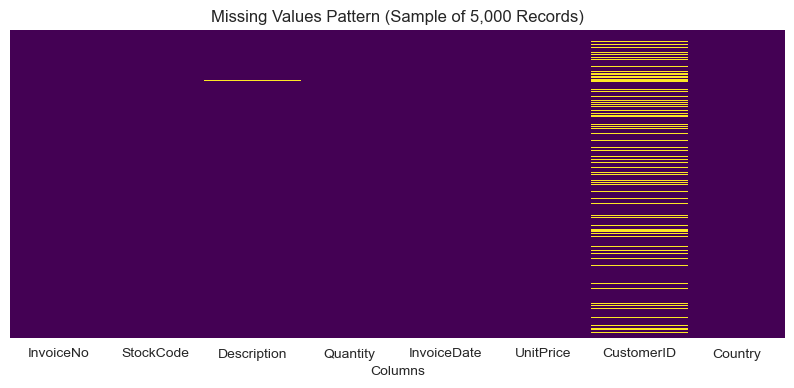

In [16]:
# Calculate missing value counts and percentages per column
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage (%)": missing_pct
})
display(missing_summary)

# Visualise missing values pattern on a random sample of 5,000 rows for fast rendering
plt.figure(figsize=(10, 4))
sns.heatmap(df.sample(5000, random_state=42).isnull(), yticklabels=False, cbar=False, cmap="viridis")
plt.title("Missing Values Pattern (Sample of 5,000 Records)")
plt.xlabel("Columns")
plt.show()

#### 3.1.2 Exact Duplicate Records
Exact duplicates across all eight columns can distort order counts and total revenue if left untreated.

In [18]:
# Count exact duplicate rows across all columns
duplicate_count = df.duplicated().sum()
duplicate_pct = round((duplicate_count / len(df)) * 100, 2)

print(f"Exact duplicate rows: {duplicate_count:,} ({duplicate_pct}%)")

# Display a sample of duplicated records
df[df.duplicated(keep=False)].sort_values(by=["InvoiceNo", "StockCode"]).head(10)

Exact duplicate rows: 5,268 (0.97%)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


#### 3.1.3 Cancelled Transactions and Non-Positive Quantities
In this dataset, invoice numbers starting with `'C'` indicate cancelled transactions. We inspect both cancelled invoices and any non-cancelled rows with zero or negative quantities.

In [20]:
# Identify cancelled invoices (InvoiceNo starting with 'C')
is_cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
cancelled_df = df[is_cancelled]

# Summarise cancellations and non-positive quantities
print(f"Cancelled line items: {len(cancelled_df):,}")
print(f"Unique cancelled invoices: {cancelled_df['InvoiceNo'].nunique():,}")
print(f"Total rows with Quantity <= 0: {(df['Quantity'] <= 0).sum():,}")
print(f"Non-cancelled rows with Quantity <= 0: {((~is_cancelled) & (df['Quantity'] <= 0)).sum():,}")

# Preview sample cancelled transactions
cancelled_df.head()

Cancelled line items: 9,288
Unique cancelled invoices: 3,836
Total rows with Quantity <= 0: 10,624
Non-cancelled rows with Quantity <= 0: 1,336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


#### 3.1.4 Invalid Unit Prices and Non-Standard Stock Codes
Next, we examine records with negative or zero unit prices, as well as non-standard stock codes that do not start with a digit. These entries are inspected first without automatically assuming they are invalid, as they may represent postage charges, discounts, service fees, or accounting adjustments.

In [22]:
# Inspect negative and zero unit prices
neg_price_df = df[df["UnitPrice"] < 0]
zero_price_df = df[df["UnitPrice"] == 0]

print(f"Rows with negative UnitPrice: {len(neg_price_df):,}")
print(f"Rows with zero UnitPrice: {len(zero_price_df):,}")
display(neg_price_df)

# Inspect StockCodes that do not start with a digit (non-standard / administrative codes)
non_product_mask = ~df["StockCode"].astype(str).str[0].str.isdigit()
print(f"\nRows with non-standard StockCode: {non_product_mask.sum():,}")
print(df.loc[non_product_mask, "StockCode"].value_counts().head(15))

Rows with negative UnitPrice: 2
Rows with zero UnitPrice: 2,515


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



Rows with non-standard StockCode: 2,995
StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
gift_0001_20      10
gift_0001_10       9
gift_0001_30       8
DCGS0003           5
Name: count, dtype: int64


#### 3.1.5 Outlier Detection (IQR Proximity Rule & Extreme Orders)
Following the **IQR Proximity Rule** (`Q1 - 1.5 * IQR` and `Q3 + 1.5 * IQR`) and boxplots, we examine the spread of `Quantity` and `UnitPrice` on positive records. We also inspect the largest positive and negative quantities side by side to verify whether extreme orders represent legitimate wholesale purchases or reversed transactions.

Quantity: Q1=1.00, Q3=10.00, IQR=9.00, Lower Fence=-12.50, Upper Fence=23.50, Outliers=56,363
UnitPrice: Q1=1.25, Q3=4.13, IQR=2.88, Lower Fence=-3.07, Upper Fence=8.45, Outliers=37,999


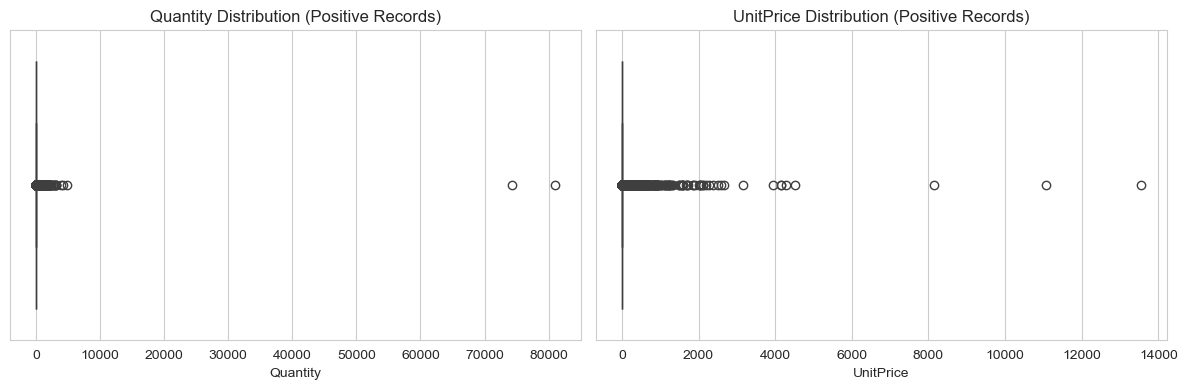

In [24]:
# Filter positive records only for outlier assessment
pos_df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Calculate IQR bounds and outlier counts
for col in ["Quantity", "UnitPrice"]:
    Q1 = pos_df[col].quantile(0.25)
    Q3 = pos_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = ((pos_df[col] < lower) | (pos_df[col] > upper)).sum()
    print(
        f"{col}: Q1={Q1:.2f}, Q3={Q3:.2f}, "
        f"IQR={IQR:.2f}, Lower Fence={lower:.2f}, "
        f"Upper Fence={upper:.2f}, Outliers={outlier_count:,}"
    )

# Plot boxplots to visualise extreme values
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=pos_df["Quantity"], ax=axes[0])
axes[0].set_title("Quantity Distribution (Positive Records)")
sns.boxplot(x=pos_df["UnitPrice"], ax=axes[1])
axes[1].set_title("UnitPrice Distribution (Positive Records)")
plt.tight_layout()
plt.show()

In [25]:
# Compare the top 5 largest positive quantities against the top 5 largest negative quantities
cols_to_show = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID"]

print("Top 5 Largest Positive Quantities:")
display(df.sort_values(by="Quantity", ascending=False)[cols_to_show].head(5))

print("\nTop 5 Largest Negative Quantities (Returns / Cancellations):")
display(df.sort_values(by="Quantity", ascending=True)[cols_to_show].head(5))

Top 5 Largest Positive Quantities:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,16446.0
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,12346.0
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,2011-11-25 15:57:00,13256.0
74614,542504,37413,NaN,5568,0.00,2011-01-28 12:03:00,NaN
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,2011-10-27 12:26:00,12901.0



Top 5 Largest Negative Quantities (Returns / Cancellations):


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,2011-12-09 09:27:00,16446.0
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,2011-01-18 10:17:00,12346.0
225529,556690,23005,printing smudges/thrown away,-9600,0.00,2011-06-14 10:37:00,NaN
225530,556691,23005,printing smudges/thrown away,-9600,0.00,2011-06-14 10:37:00,NaN
4287,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,0.03,2010-12-02 14:23:00,15838.0


#### 3.1.6 Data Quality Findings & Cleaning Strategy

The systematic data quality assessment identified several issues that require careful consideration before proceeding with data cleaning:

- **Missing Values:** The `CustomerID` column contains **135,080 missing values (24.93%)**, while `Description` contains **1,454 missing values (0.27%)**. Missing customer identifiers limit customer-level analysis, but these transactions can still contribute to overall sales analysis. Missing descriptions will require further investigation.
- **Duplicate Records:** A total of **5,268 exact duplicate rows** were identified, representing approximately **0.97%** of the dataset. These records may inflate transaction counts and revenue if retained without assessment; their removal will be performed during the cleaning stage.
- **Cancelled Transactions and Quantities:** The dataset contains **9,288 cancelled line items** across **3,836 unique cancelled invoices**. Additionally, **10,624 records** have non-positive quantities, including **1,336 records** without a cancellation invoice prefix (such as damaged or written-off stock). These records will be investigated separately before applying final filters.
- **Unit Prices and Stock Codes:** Two records contain negative unit prices (`-11,062.06`); both are described as `Adjust bad debt` under `StockCode` `B`, indicating accounting adjustments rather than ordinary product sales. A further **2,515 records** have zero unit prices, which may represent free items, damaged stock write-offs, or unpriced entries. The assessment also identified **2,995 records** with non-standard stock codes (`POST`, `DOT`, `M`, `C2`, `D`, etc.), which will be inspected by description and business purpose rather than automatically removed.
- **Outliers and Extreme Transactions:** The IQR method (`1.5 × IQR`) identified **56,363 statistical outliers** in `Quantity` (Upper Fence = `23.50`) and **37,999** in `UnitPrice` (Upper Fence = `8.45`) among positive records. Because this is a wholesale business, statistical outliers are not automatically treated as errors.
- **Reversed Extreme Orders:** Two exceptionally large transactions were verified directly against the cancellation records:
  - Invoice `581483` (`Quantity = +80,995`, `UnitPrice = £2.08`) was followed **12 minutes later** by cancellation `C581484` (`Quantity = -80,995`) for the exact same product, customer, and price.
  - Invoice `541431` (`Quantity = +74,215`, `UnitPrice = £1.04`) was followed **16 minutes later** by cancellation `C541433` (`Quantity = -74,215`) for the exact same product, customer, and price.
  - These matching records provide strong evidence that both extreme transactions were reversed and should not inflate net sales.

**Proposed Cleaning Strategy (keeping the original `df` intact and creating a cleaned DataFrame `df_clean`):**
1. Remove exact duplicate records (`drop_duplicates(keep='first')`) after confirming their impact.
2. Exclude cancelled transactions (`InvoiceNo` starting with `'C'`) and the two confirmed reversed extreme invoices (`581483`, `541431`) from the main sales analysis, while keeping `df` intact for audit and cancellation analysis.
3. Inspect and handle non-positive quantities without a `'C'` prefix and zero-price transactions based on their descriptions.
4. Inspect non-standard `StockCode` entries (`POST`, `DOT`, `M`, `B`, `D`, etc.) and separate accounting adjustments / non-product fees from physical product sales where appropriate.
5. Retain missing `CustomerID` records in `df_clean` for overall revenue analysis, and filter `notnull()` only for customer-level analyses.
6. Preserve legitimate wholesale high-volume orders, combining business context with statistical checks (as covered in Week 7).

No records have been removed or modified during this assessment. The proposed actions will be implemented and validated step by step in **Section 3.2: Data Cleaning**.